In [14]:
%pip install kagglehub --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
import kagglehub
path = kagglehub.dataset_download("hojjatk/mnist-dataset")
print("path to dataset files:", path)

path to dataset files: C:\Users\Анна\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1


In [16]:
import os
import struct
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
import seaborn as sns

def read_idx_images(path):
    with open(path, 'rb') as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        assert magic == 2051, f"неверный magic number: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
        data = data.reshape(n, rows * cols)
    return data.astype(np.float32)

def read_idx_labels(path):
    with open(path, 'rb') as f:
        magic, n = struct.unpack(">II", f.read(8))
        assert magic == 2049, f"неверный magic number: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.astype(int)

def load_mnist_idx(root_dir):
    root = Path(root_dir)
    def find_file(*candidates):
        for name in candidates:
            p = root / name
            if p.exists(): return p
            for sub in root.rglob(name): return sub
        raise FileNotFoundError(f"не найден файл среди: {candidates} в {root_dir}")

    train_images = find_file("train-images.idx3-ubyte", "train-images-idx3-ubyte")
    train_labels = find_file("train-labels.idx1-ubyte", "train-labels-idx1-ubyte")
    test_images  = find_file("t10k-images.idx3-ubyte", "t10k-images-idx3-ubyte")
    test_labels  = find_file("t10k-labels.idx1-ubyte", "t10k-labels-idx1-ubyte")

    X_train_full = read_idx_images(train_images)
    y_train_full = read_idx_labels(train_labels)
    X_test       = read_idx_images(test_images)
    y_test       = read_idx_labels(test_labels)
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.1, random_state=42, stratify=y_train_full
    )

    X_train = X_train / 255.0
    X_val   = X_val   / 255.0
    X_test  = X_test  / 255.0

    return X_train, y_train, X_val, y_val, X_test, y_test

train: (54000, 784), val: (6000, 784), test: (10000, 784)


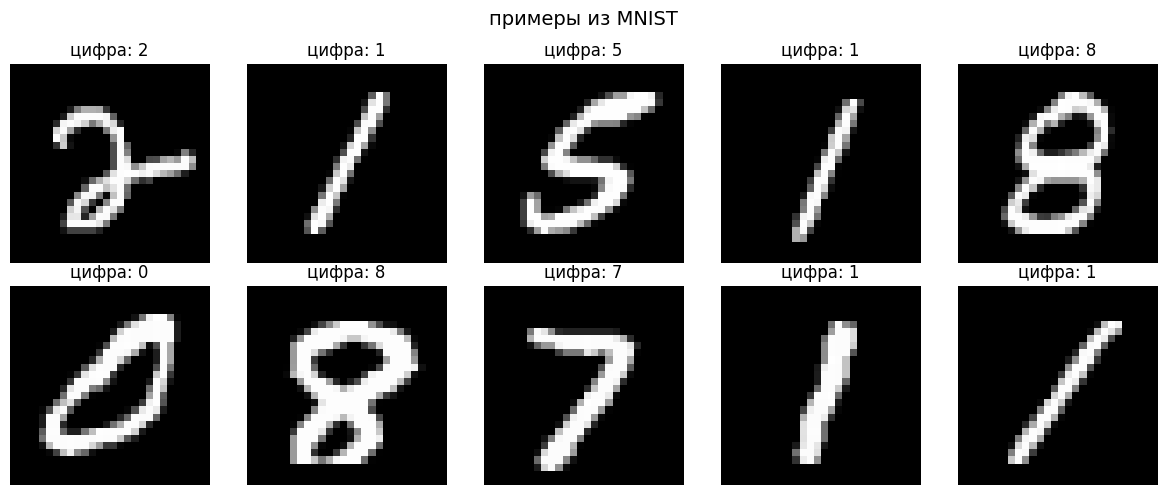

In [17]:
X_train, y_train, X_val, y_val, X_test, y_test = load_mnist_idx(path)
print(f"train: {X_train.shape}, val: {X_val.shape}, test: {X_test.shape}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"цифра: {y_train[i]}")
    ax.axis('off')
plt.suptitle("примеры из MNIST", fontsize=14)
plt.tight_layout()
plt.show()

In [18]:
tree_full = DecisionTreeClassifier(random_state=42)
tree_full.fit(X_train, y_train)
print(f"дерево (без ограничений): train={accuracy_score(y_train, tree_full.predict(X_train)):.3f}, "
      f"val={accuracy_score(y_val, tree_full.predict(X_val)):.3f}")

tree_shallow = DecisionTreeClassifier(max_depth=10, random_state=42)
tree_shallow.fit(X_train, y_train)
print(f"дерево (max_depth=10):    train={accuracy_score(y_train, tree_shallow.predict(X_train)):.3f}, "
      f"val={accuracy_score(y_val, tree_shallow.predict(X_val)):.3f}")

дерево (без ограничений): train=1.000, val=0.875
дерево (max_depth=10):    train=0.904, val=0.854


 random Forest: train=0.998, val=0.961


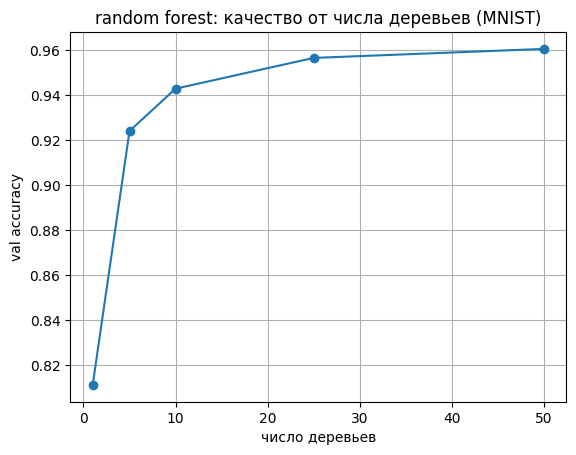

In [19]:
rf = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42)
rf.fit(X_train, y_train)
print(f" random Forest: train={accuracy_score(y_train, rf.predict(X_train)):.3f}, "
      f"val={accuracy_score(y_val, rf.predict(X_val)):.3f}")

n_range = [1, 5, 10, 25, 50]
val_scores = []
for n in n_range:
    rf_n = RandomForestClassifier(n_estimators=n, max_depth=15, random_state=42)
    rf_n.fit(X_train, y_train)
    val_scores.append(accuracy_score(y_val, rf_n.predict(X_val)))

plt.plot(n_range, val_scores, marker='o')
plt.xlabel("число деревьев")
plt.ylabel("val accuracy")
plt.title("random forest: качество от числа деревьев (MNIST)")
plt.grid(True)
plt.show()

In [20]:
from sklearn.ensemble import GradientBoostingClassifier

X_train_sub = X_train[:5000]
y_train_sub = y_train[:5000]

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                 max_depth=3, random_state=42)
gb.fit(X_train_sub, y_train_sub)

train_acc = accuracy_score(y_train_sub, gb.predict(X_train_sub))
val_acc   = accuracy_score(y_val,   gb.predict(X_val))
print(f"Gradient Boosting: train={train_acc:.3f}, val={val_acc:.3f}")

Gradient Boosting: train=0.999, val=0.914


In [21]:
models = {
    "Decision Tree (full)":    tree_full,
    "Decision Tree (depth=10)": tree_shallow,
    "Random Forest":           rf,
    "Gradient Boosting":       gb,
}

print("метрики на тесте")
for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average='macro') 
    print(f"{name:25s} | accuracy={acc:.3f} | Macro-F1={f1:.3f}")
    
print("\nдетальный отчет (Random Forest):")
print(classification_report(y_test, rf.predict(X_test), 
                            target_names=[str(i) for i in range(10)]))

метрики на тесте
Decision Tree (full)      | accuracy=0.868 | Macro-F1=0.866
Decision Tree (depth=10)  | accuracy=0.863 | Macro-F1=0.861
Random Forest             | accuracy=0.964 | Macro-F1=0.964
Gradient Boosting         | accuracy=0.921 | Macro-F1=0.921

детальный отчет (Random Forest):
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.96      0.97      0.96      1032
           3       0.96      0.96      0.96      1010
           4       0.97      0.95      0.96       982
           5       0.97      0.96      0.97       892
           6       0.97      0.97      0.97       958
           7       0.97      0.95      0.96      1028
           8       0.95      0.95      0.95       974
           9       0.93      0.95      0.94      1009

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weigh

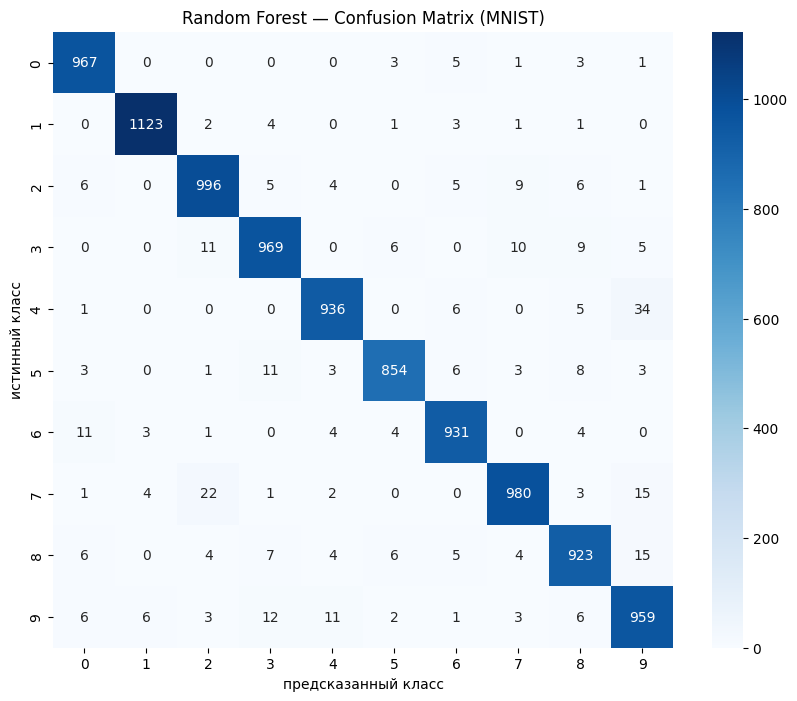

In [22]:
cm = confusion_matrix(y_test, rf.predict(X_test))
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[str(i) for i in range(10)],
            yticklabels=[str(i) for i in range(10)])
plt.ylabel("истинный класс")
plt.xlabel("предсказанный класс")
plt.title("Random Forest — Confusion Matrix (MNIST)")
plt.show()